In [1]:
import sys
import torch
import transformers

print("Python: ", sys.version)
print("PyTorch: ", torch.__version__)
print("CUDA available: ", torch.cuda.is_available())
print("Transformers: ", transformers.__version__)


Python:  3.12.14 | packaged by Anaconda, Inc. | (main, Aug 27 2026, 14:37:13) [MSC v.1942 64 bit (AMD64)]
PyTorch:  2.14.0+cpu
CUDA available:  False
Transformers:  5.17.0


In [2]:
from transformers import AutoTokenizer, AutoModelForCausalLM

In [3]:
# model_name = "distilgpt2"

# tokenizer = AutoTokenizer.from_pretrained(model_name)
# model = AutoModelForCausalLM.from_pretrained(model_name)

# print("Model loaded:", model_name)


In [4]:
# model_name = "Qwen2.5-0.5B-Instruct"

# tokenizer = AutoTokenizer.from_pretrained(model_name)
# model = AutoModelForCausalLM.from_pretrained(model_name)

# print("Model loaded:", model_name)

In [5]:
model_name= "Qwen/Qwen2.5-1.5B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForCausalLM.from_pretrained(model_name)

print("Model Loaded:", model_name)

Loading weights: 100%|██████████| 338/338 [00:02<00:00, 117.93it/s]


Model Loaded: Qwen/Qwen2.5-1.5B-Instruct


In [6]:
# First inference test 

prompt = "Explain what artificial intelligence is in one sentence."

messages = [
    {"role":"user","content":prompt}
]

text = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True
)

inputs = tokenizer(text, return_tensors="pt")

print("Input tokens: ", inputs["input_ids"].shape)

Input tokens:  torch.Size([1, 39])


In [7]:
# Response Generation

outputs = model.generate(
    **inputs,
    max_new_tokens=50
)

response = tokenizer.decode(
    outputs[0][inputs["input_ids"].shape[1]:],
    skip_special_tokens=True
)

print(response)

Artificial Intelligence (AI) refers to the simulation of human intelligence processes by machines, especially computer systems, so that they can work and react like humans.


Number of tokens: 39

Tokens:
['<|im_start|>', 'system', 'Ċ', 'You', 'Ġare', 'ĠQ', 'wen', ',', 'Ġcreated', 'Ġby', 'ĠAlibaba', 'ĠCloud', '.', 'ĠYou', 'Ġare', 'Ġa', 'Ġhelpful', 'Ġassistant', '.', '<|im_end|>', 'Ċ', '<|im_start|>', 'user', 'Ċ', 'Ex', 'plain', 'Ġwhat', 'Ġartificial', 'Ġintelligence', 'Ġis', 'Ġin', 'Ġone', 'Ġsentence', '.', '<|im_end|>', 'Ċ', '<|im_start|>', 'assistant', 'Ċ']


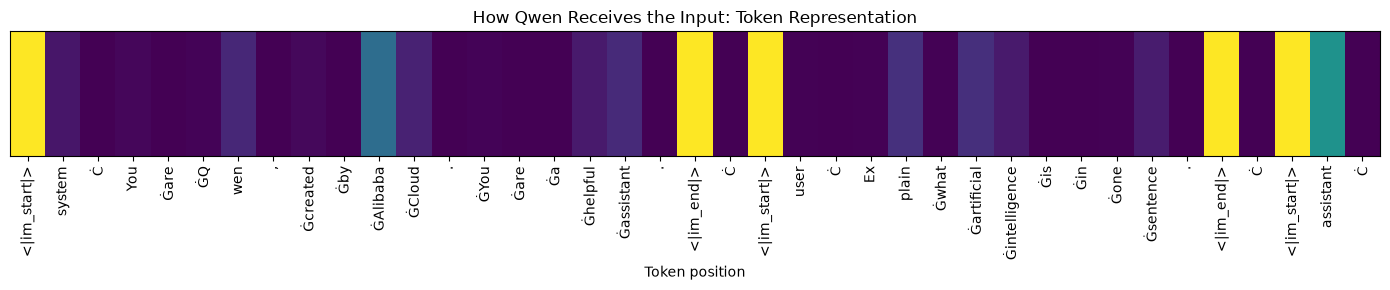

In [8]:
# Lets Inspect what Qwen model actually sees

import matplotlib.pyplot as plt

token_ids = inputs["input_ids"][0].tolist()
tokens = tokenizer.convert_ids_to_tokens(token_ids)

print("Number of tokens:", len(tokens))
print("\nTokens:")
print(tokens)

plt.figure(figsize=(14, 3))
plt.imshow([token_ids], aspect="auto")

plt.xticks(range(len(tokens)), tokens, rotation=90)
plt.yticks([])
plt.xlabel("Token position")
plt.title("How Qwen Receives the Input: Token Representation")
plt.tight_layout()
plt.show()


In [9]:
# Create Chunking Model
## Long Context - TEST

long_text = """
Artificial intelligence has become an important part of modern software development,
with applications ranging from recommendation systems and fraud detection to natural
language processing and autonomous systems. Large language models have expanded this
area by allowing software applications to understand and generate human language.
These models process text as tokens and use Transformer-based architectures to determine
relationships between different parts of the input. However, as the amount of text grows,
the computational cost of processing relationships between tokens can also increase.

Attention mechanisms are particularly important because they determine which parts of
the input should influence the representation of other parts. Global attention allows
tokens to interact with information from the entire input sequence, which can be useful
when the meaning of a sentence depends on information introduced much earlier. Local
attention, on the other hand, restricts interactions to a smaller surrounding region.
This can reduce the amount of computation while still preserving nearby contextual
information. The choice between local and global attention therefore creates a trade-off
between computational efficiency and the amount of context available to the model.

For a conversational AI system, this distinction becomes even more important because
users may provide long messages containing several related ideas. A chatbot may need
to remember information from an earlier part of the conversation while generating a
response to a later question. Splitting a long message into manageable chunks allows
the system to organize the input before applying an attention strategy. The chatbot can
then use a local attention mode when nearby context is sufficient or a global attention
mode when information from the entire message is important. This project demonstrates
how text chunking and adjustable attention can be combined with a pretrained language
model to create a simple context-aware chatbot.
"""

print(long_text)



Artificial intelligence has become an important part of modern software development,
with applications ranging from recommendation systems and fraud detection to natural
language processing and autonomous systems. Large language models have expanded this
area by allowing software applications to understand and generate human language.
These models process text as tokens and use Transformer-based architectures to determine
relationships between different parts of the input. However, as the amount of text grows,
the computational cost of processing relationships between tokens can also increase.

Attention mechanisms are particularly important because they determine which parts of
the input should influence the representation of other parts. Global attention allows
tokens to interact with information from the entire input sequence, which can be useful
when the meaning of a sentence depends on information introduced much earlier. Local
attention, on the other hand, restricts interactions

In [12]:
# Chunking function

import re

def split_into_chunks(text):
    sentences = re.split(r'(?<=[.!?])\s+', text.strip())
    return sentences

chunks = split_into_chunks(long_text)

print("Number of Chunks :", len(chunks))

for i, chunk in enumerate(chunks, start=1):
    print(f"\nChunk {i}:")
    print(chunk)
    

Number of Chunks : 14

Chunk 1:
Artificial intelligence has become an important part of modern software development,
with applications ranging from recommendation systems and fraud detection to natural
language processing and autonomous systems.

Chunk 2:
Large language models have expanded this
area by allowing software applications to understand and generate human language.

Chunk 3:
These models process text as tokens and use Transformer-based architectures to determine
relationships between different parts of the input.

Chunk 4:
However, as the amount of text grows,
the computational cost of processing relationships between tokens can also increase.

Chunk 5:
Attention mechanisms are particularly important because they determine which parts of
the input should influence the representation of other parts.

Chunk 6:
Global attention allows
tokens to interact with information from the entire input sequence, which can be useful
when the meaning of a sentence depends on information int

In [13]:
# Inspect Chunk lengths

for i, chunk in enumerate(chunks, start=1):
    token_count = len(tokenizer.encode(chunk, add_special_tokens=False))
    print(f"Chunk {i}: {token_count} tokens")

Chunk 1: 31 tokens
Chunk 2: 19 tokens
Chunk 3: 22 tokens
Chunk 4: 21 tokens
Chunk 5: 22 tokens
Chunk 6: 33 tokens
Chunk 7: 18 tokens
Chunk 8: 15 tokens
Chunk 9: 26 tokens
Chunk 10: 25 tokens
Chunk 11: 26 tokens
Chunk 12: 22 tokens
Chunk 13: 31 tokens
Chunk 14: 29 tokens


In [14]:
# The assignment's workflow specifically describes splitting input into uniform token chunks before applying the attention strategy.

# Create 32-Token sized chunks

tokens = tokenizer.encode(
    long_text,
    add_special_token = False
)

chunk_size = 32

token_chunks = [
    tokens[i:i + chunk_size]
    for i in range(0,len(tokens), chunk_size)
]

print("Total Tokens :", len(tokens))
print("Number of Token Chunks :", len(token_chunks))

for i, chunk in enumerate(token_chunks, start=1):
    print(f"Chunk {i}: {len(chunk)} tokens")

Total Tokens : 341
Number of Token Chunks : 11
Chunk 1: 32 tokens
Chunk 2: 32 tokens
Chunk 3: 32 tokens
Chunk 4: 32 tokens
Chunk 5: 32 tokens
Chunk 6: 32 tokens
Chunk 7: 32 tokens
Chunk 8: 32 tokens
Chunk 9: 32 tokens
Chunk 10: 32 tokens
Chunk 11: 21 tokens


In [16]:
# Lets Check by converting Token IDs to Readable Text

for i, chunk in enumerate(token_chunks, start=1):
    decoded_chunk = tokenizer.decode(chunk)
    
    print(f"\n--- Chunk {i} ---")
    print(decoded_chunk)


--- Chunk 1 ---

Artificial intelligence has become an important part of modern software development,
with applications ranging from recommendation systems and fraud detection to natural
language processing and autonomous systems.

--- Chunk 2 ---
 Large language models have expanded this
area by allowing software applications to understand and generate human language.
These models process text as tokens and use Transformer-based architectures to determine

--- Chunk 3 ---

relationships between different parts of the input. However, as the amount of text grows,
the computational cost of processing relationships between tokens can also increase.

Attention mechanisms

--- Chunk 4 ---
 are particularly important because they determine which parts of
the input should influence the representation of other parts. Global attention allows
tokens to interact with information from the entire

--- Chunk 5 ---
 input sequence, which can be useful
when the meaning of a sentence depends on inform

In [18]:
# Adjustable Attention

## Local Attention Mask

window_size = 2

sequence_len = len(token_chunks[0])

local_mask = torch.zeros(
    (sequence_len, sequence_len),
    dtype=torch.int
)

for i in range(sequence_len):
    for j in range(sequence_len):
        if abs(i-j) <= window_size:
            local_mask[i, j] = 1
print("Local attention mask shape: ", local_mask.shape)
print(local_mask)



Local attention mask shape:  torch.Size([32, 32])
tensor([[1, 1, 1,  ..., 0, 0, 0],
        [1, 1, 1,  ..., 0, 0, 0],
        [1, 1, 1,  ..., 0, 0, 0],
        ...,
        [0, 0, 0,  ..., 1, 1, 1],
        [0, 0, 0,  ..., 1, 1, 1],
        [0, 0, 0,  ..., 1, 1, 1]], dtype=torch.int32)


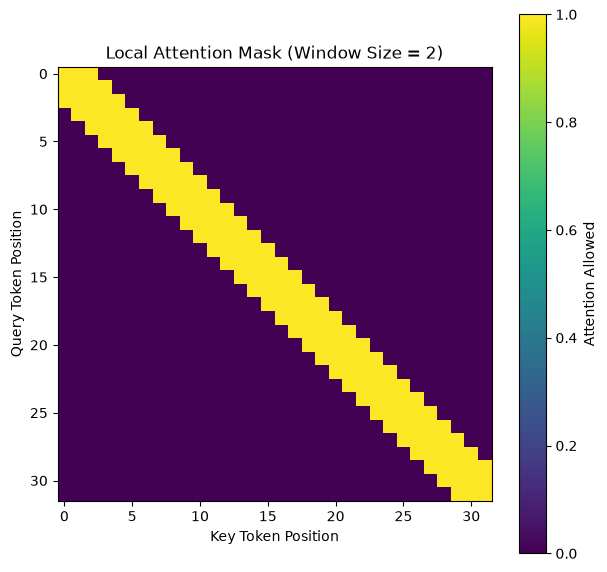

In [19]:
#  visual representations of Local Attention

plt.figure(figsize=(7, 7))

plt.imshow(local_mask)

plt.xlabel("Key Token Position")
plt.ylabel("Query Token Position")
plt.title("Local Attention Mask (Window Size = 2)")

plt.colorbar(label="Attention Allowed")

plt.show()

In [20]:
# Local Attention Mode: restricts each token's attention to a fixed surrounding window, reducing the number of token-to-token interactions compared with full attention.


In [21]:
# Global Attention
## where every token can attend to every other token.

global_mask = torch.ones(
    (sequence_len, sequence_len),
    dtype = torch.int
)

print("Global Attention Mask Shape: ", global_mask.shape)
print(global_mask)

Global Attention Mask Shape:  torch.Size([32, 32])
tensor([[1, 1, 1,  ..., 1, 1, 1],
        [1, 1, 1,  ..., 1, 1, 1],
        [1, 1, 1,  ..., 1, 1, 1],
        ...,
        [1, 1, 1,  ..., 1, 1, 1],
        [1, 1, 1,  ..., 1, 1, 1],
        [1, 1, 1,  ..., 1, 1, 1]], dtype=torch.int32)


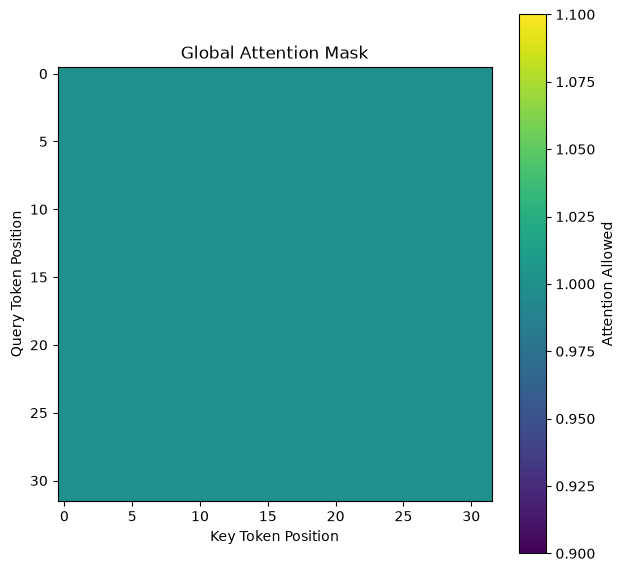

In [22]:
# Visual Representation of Global/Full Attention 

plt.figure(figsize=(7, 7))

plt.imshow(global_mask)

plt.xlabel("Key Token Position")
plt.ylabel("Query Token Position")
plt.title("Global Attention Mask")

plt.colorbar(label="Attention Allowed")

plt.show()

In [24]:
# A reusable Attention Control Panel function.

def create_attention_mask(sequence_len, mode="local", window_size=2):

    if mode == "local":
        mask = torch.zeros((sequence_len,sequence_len), dtype=torch.int)

        for i in range(sequence_len):
            for j in range(sequence_len):
                if abs(i-j)<= window_size:
                    mask[i, j] = 1
    elif mode == "global":
        mask = torch.ones((sequence_len, sequence_len), dtype=torch.int)

    else:
        raise ValueError("Mode must be 'local' or 'global'")

    return mask
        

In [27]:
# LOCAL MODE TEST
mode = "local"

selected_mask = create_attention_mask(
    sequence_len=32,
    mode=mode,
    window_size=2
)

print("Selected mode:", mode)
print("Mask shape:", selected_mask.shape)

Selected mode: local
Mask shape: torch.Size([32, 32])


In [28]:
# GLOBAL MODE TEST

mode = "global"

selected_mask = create_attention_mask(
    sequence_len=32,
    mode=mode,
    window_size=2
)

print("Selected mode:", mode)
print("Mask shape:", selected_mask.shape)


Selected mode: global
Mask shape: torch.Size([32, 32])


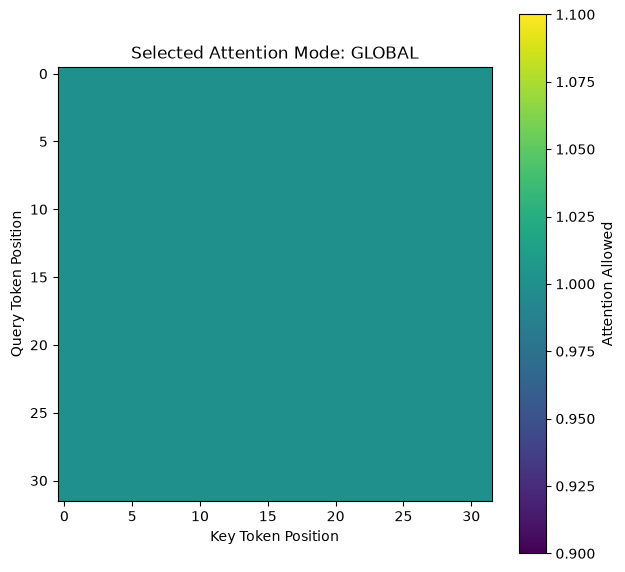

In [29]:
# Visual Representation based on MODE

plt.figure(figsize=(7, 7))

plt.imshow(selected_mask)

plt.xlabel("Key Token Position")
plt.ylabel("Query Token Position")
plt.title(f"Selected Attention Mode: {mode.upper()}")

plt.colorbar(label="Attention Allowed")

plt.show()

In [32]:
# Attention Calculation

import torch.nn.functional as F

query = torch.randn(1, 32, 8)
key = torch.randn(1, 32, 8)
value = torch.randn(1, 32, 8)

scores = torch.matmul(query, key.transpose(-2, -1))

print("Attention score shape:", scores.shape)

masked_scores = scores.masked_fill(
    selected_mask == 0,
    -1e9 #we'll apply Softmax. A very negative number becomes essentially zero attention probability
)

print("Masked score shape:", masked_scores.shape)

Attention score shape: torch.Size([1, 32, 32])
Masked score shape: torch.Size([1, 32, 32])


In [34]:
# Softmax -> converts its 32 raw scores into probabilities

attention_weights = F.softmax(
    masked_scores,
    dim=-1
)

print("Attention weights shape:", attention_weights.shape)

Attention weights shape: torch.Size([1, 32, 32])


In [35]:
# LOCAL MODE - attention weight TEST

mode = "local"

selected_mask = create_attention_mask(
    sequence_len=32,
    mode=mode,
    window_size=2
)

masked_scores = scores.masked_fill(
    selected_mask == 0,
    -1e9
)

attention_weights = F.softmax(
    masked_scores,
    dim=-1
)

print("Mode:", mode)
print("Attention weights shape:", attention_weights.shape)

Mode: local
Attention weights shape: torch.Size([1, 32, 32])


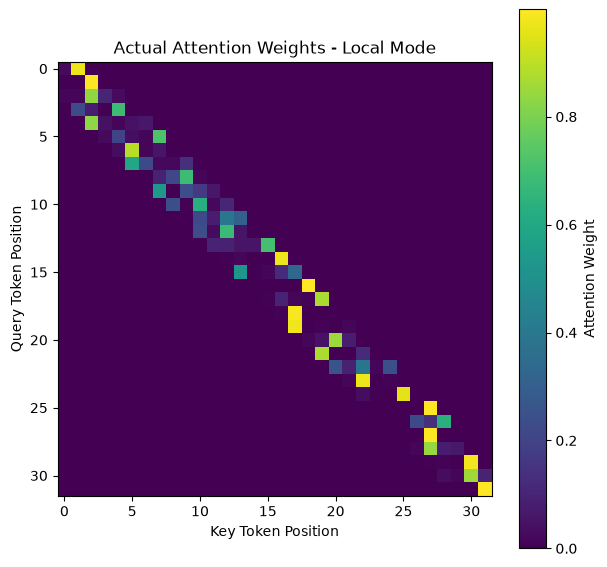

In [36]:
# Visuals  -> Actual Weights

plt.figure(figsize=(7, 7))

plt.imshow(attention_weights[0].detach().numpy())

plt.xlabel("Key Token Position")
plt.ylabel("Query Token Position")
plt.title("Actual Attention Weights - Local Mode")

plt.colorbar(label="Attention Weight")

plt.show()

In [37]:
# Check blocked positions really have Zero attention. 

print("Maximum attention outside local window:")

outside_window = selected_mask == 0

print(
    attention_weights[0][outside_window].max().item()
)

Maximum attention outside local window:
0.0


In [38]:
# Using attention weights to combine Vector (Value)

attention_output = torch.matmul(
    attention_weights,
    value
)

print("Attention output shape: ", attention_output.shape)



Attention output shape:  torch.Size([1, 32, 8])


In [39]:
print(model.model.layers[0])

Qwen2DecoderLayer(
  (self_attn): Qwen2Attention(
    (q_proj): Linear(in_features=1536, out_features=1536, bias=True)
    (k_proj): Linear(in_features=1536, out_features=256, bias=True)
    (v_proj): Linear(in_features=1536, out_features=256, bias=True)
    (o_proj): Linear(in_features=1536, out_features=1536, bias=False)
  )
  (mlp): Qwen2MLP(
    (gate_proj): Linear(in_features=1536, out_features=8960, bias=False)
    (up_proj): Linear(in_features=1536, out_features=8960, bias=False)
    (down_proj): Linear(in_features=8960, out_features=1536, bias=False)
    (act_fn): SiLUActivation()
  )
  (input_layernorm): Qwen2RMSNorm((1536,), eps=1e-06)
  (post_attention_layernorm): Qwen2RMSNorm((1536,), eps=1e-06)
)


In [41]:
# verify different output between Local and Global modes

local_mask = create_attention_mask(
    sequence_len=32,
    mode="local",
    window_size=2
)

global_mask = create_attention_mask(
    sequence_len=32,
    mode="global"
)

local_scores = scores.masked_fill(local_mask == 0, -1e9)
global_scores = scores.masked_fill(global_mask == 0, -1e9)

local_weights = F.softmax(local_scores, dim=-1)
global_weights = F.softmax(global_scores, dim=-1)

local_output = torch.matmul(local_weights, value)
global_output = torch.matmul(global_weights, value)

difference = torch.mean(
    torch.abs(local_output - global_output)
)

print("Local output shape:", local_output.shape)
print("Global output shape:", global_output.shape)
print("Mean absolute difference:", difference.item())

Local output shape: torch.Size([1, 32, 8])
Global output shape: torch.Size([1, 32, 8])
Mean absolute difference: 0.6864795684814453


In [42]:
# Changing the attention mode changes which information can contribute to the resulting representation.


In [49]:
# Chatbot 

user_input = input("You: ")

print("Received:", user_input)


You:  What are some interesting places to visit in Thunder Bay, CANADA ?


Received: What are some interesting places to visit in Thunder Bay, CANADA ?


In [50]:
# User Input -> Qwen model

messages = [
    {
        "role": "user",
        "content": user_input
    }
]

text = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True
)

inputs = tokenizer(
    text,
    return_tensors="pt"
)

print("Input tokens:", inputs["input_ids"].shape)

Input tokens: torch.Size([1, 43])


In [51]:
# Output 
outputs = model.generate(
    **inputs,
    max_new_tokens=250
)

response = tokenizer.decode(
    outputs[0][inputs["input_ids"].shape[1]:],
    skip_special_tokens=True
)

print("Assistant:", response)

Assistant: Thunder Bay is the largest city in Northern Ontario, Canada and has many interesting places to visit. Some of them include:

1. Thunder Bay Zoo: This zoo features over 300 animals from all around the world.

2. Lake Superior Beaches: The beaches on Lake Superior offer beautiful views and opportunities for swimming, sunbathing, and water sports.

3. Thunder Bay National Maritime Museum: This museum showcases maritime history and culture through exhibits, artifacts, and interactive displays.

4. Fort William Historical Park: This park offers visitors an opportunity to explore the history of the area through its reconstructed fortifications and historic buildings.

5. Thunder Bay Botanical Garden: This garden features over 600 species of plants and trees from around the world.

6. Kitchenuhmayowin Provincial Park: This park offers hiking trails, fishing, and boating opportunities along the shore of Lake Superior.

7. Thunder Bay Art Gallery: This gallery hosts exhibitions of co

In [52]:
# Reusable chunk function
def create_token_chunks(text, chunk_size=32):
    tokens = tokenizer.encode(
        text,
        add_special_tokens=False
    )

    chunks = [
        tokens[i:i + chunk_size]
        for i in range(0, len(tokens), chunk_size)
    ]

    return chunks

In [53]:
# Test Reusable Chunk function

token_chunks = create_token_chunks(
    user_input,
    chunk_size=32
)

print("Total chunks:", len(token_chunks))

for i, chunk in enumerate(token_chunks, start=1):
    print(f"Chunk {i}: {len(chunk)} tokens")

Total chunks: 1
Chunk 1: 14 tokens


In [54]:
# Choose Modes
mode = input("Choose attention mode (local/global): ").lower().strip()

if mode not in ["local", "global"]:
    print("Invalid mode. Please choose local or global.")
else:
    print("Selected attention mode:", mode)

Choose attention mode (local/global):  local


Selected attention mode: local


In [56]:
# Mask for User's selected Mode

selected_mask = create_attention_mask(
    sequence_len=len(token_chunks[0]),
    mode=mode,
    window_size=2
)

print("Mode:", mode)
print("Chunk length:", len(token_chunks[0]))
print("Attention mask shape:", selected_mask.shape)

Mode: local
Chunk length: 14
Attention mask shape: torch.Size([14, 14])


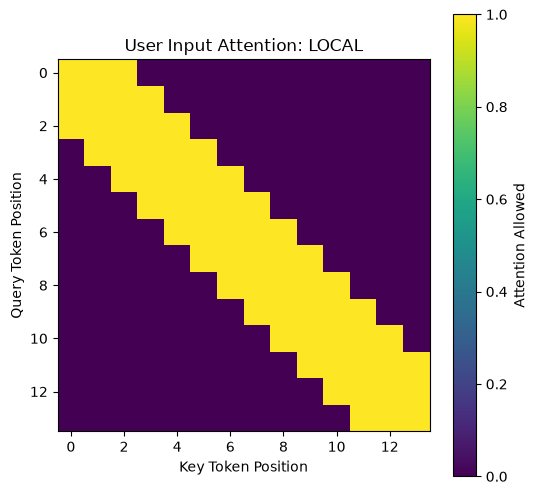

In [57]:
# Visualize user selected Attention mode

plt.figure(figsize=(6, 6))

plt.imshow(selected_mask)

plt.xlabel("Key Token Position")
plt.ylabel("Query Token Position")
plt.title(f"User Input Attention: {mode.upper()}")

plt.colorbar(label="Attention Allowed")

plt.show()

In [58]:
# Inspect Actual Decoded Chunk 
for i, chunk in enumerate(token_chunks, start=1):
    print(f"\nChunk {i}:")
    print(tokenizer.decode(chunk))


Chunk 1:
What are some interesting places to visit in Thunder Bay, CANADA ?


In [67]:
# Attention process

def process_attention(chunks, mode="local", window_size=2):
    
    processed_chunks = []

    for chunk in chunks:
        sequence_len = len(chunk)

        mask = create_attention_mask(
            sequence_len=sequence_len,
            mode=mode,
            window_size=window_size
        )

        processed_chunks.append({
            "tokens": chunk,
            "mask": mask
        })

    return processed_chunks
    

In [68]:
processed_chunks = process_attention(
    token_chunks,
    mode=mode,
    window_size=2
)

print("Attention mode:", mode)
print("Number of processed chunks:", len(processed_chunks))

for i, chunk in enumerate(processed_chunks, start=1):
    print(
        f"Chunk {i}: "
        f"{len(chunk['tokens'])} tokens, "
        f"mask shape {chunk['mask'].shape}"
    )

Attention mode: local
Number of processed chunks: 1
Chunk 1: 14 tokens, mask shape torch.Size([14, 14])


In [69]:
for i, chunk in enumerate(processed_chunks, start=1):
    mask = chunk["mask"]

    allowed = mask.sum().item()
    total = mask.numel()
    percentage = (allowed / total) * 100

    print(f"Chunk {i}:")
    print(f"  Allowed attention connections: {allowed}/{total}")
    print(f"  Attention coverage: {percentage:.2f}%")

Chunk 1:
  Allowed attention connections: 64/196
  Attention coverage: 32.65%


In [70]:
mode = "global"

processed_chunks = process_attention(
    token_chunks,
    mode=mode,
    window_size=2
)

for i, chunk in enumerate(processed_chunks, start=1):
    mask = chunk["mask"]

    allowed = mask.sum().item()
    total = mask.numel()
    percentage = (allowed / total) * 100

    print(f"Chunk {i}:")
    print(f"  Allowed attention connections: {allowed}/{total}")
    print(f"  Attention coverage: {percentage:.2f}%")

Chunk 1:
  Allowed attention connections: 196/196
  Attention coverage: 100.00%


In [88]:
# Prepare Context

def prepare_context(processed_chunks):
    
    context_parts = []

    for chunk in processed_chunks:
        text = tokenizer.decode(
            chunk["tokens"],
            skip_special_tokens=True
        )

        context_parts.append(text)

    return " ".join(context_parts)

In [89]:
# TEST
context = prepare_context(processed_chunks)

print("Prepared context:")
print(context)

Prepared context:

I am planning a trip around Thunder Bay and want to explore nature, history,
food, and activities. I am especially interested in places around Lake Superior,
 waterfalls, hiking trails, historical locations, museums, parks, and viewpoints.
I also want to know which places are suitable for a short weekend visit and which 
ones require more time. Please organize the suggestions by category and explain
why each place might be interesting.



In [90]:
# Generate the chatbot response
messages = [
    {
        "role": "user",
        "content": context
    }
]

text = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True
)

inputs = tokenizer(
    text,
    return_tensors="pt"
)

outputs = model.generate(
    **inputs,
    max_new_tokens=200
)

response = tokenizer.decode(
    outputs[0][inputs["input_ids"].shape[1]:],
    skip_special_tokens=True
)

print("Assistant:")
print(response)

Assistant:
Certainly! Here's an organized list of places you can consider visiting around Thunder Bay, focusing on natural attractions, historical sites, cultural experiences, and recreational opportunities:

### Nature and Waterfall Hiking
1. **Thunder Bay National Park**
   - *Description:* This park offers diverse landscapes including forests, lakes, and rivers. It’s great for hiking and exploring the natural beauty of the region.
   
2. **Muskaxia Falls Provincial Park**
   - *Description:* Located near Thunder Bay, this park is known for its beautiful waterfalls and scenic views. The area is ideal for both day hikes and camping.

3. **Chippawa Falls Provincial Park**
   - *Description:* Situated just outside Thunder Bay, this park features Chippawa Falls, one of Canada's largest waterfalls. It provides easy access with several walking trails.

4. **Sturgeon River Provincial Park**
   - *Description:* Known for its abundant wildlife, Sturgeon River is perfect for canoe


In [91]:
# TESTING LONG CONTEXT

long_user_input = """
I am planning a trip around Thunder Bay and want to explore nature, history,
food, and activities. I am especially interested in places around Lake Superior,
waterfalls, hiking trails, historical locations, museums, parks, and viewpoints.
I also want to know which places are suitable for a short weekend visit and which
ones require more time. Please organize the suggestions by category and explain
why each place might be interesting.
"""

token_chunks = create_token_chunks(
    long_user_input,
    chunk_size=32
)

print("Total tokens:", sum(len(chunk) for chunk in token_chunks))
print("Number of chunks:", len(token_chunks))

for i, chunk in enumerate(token_chunks, start=1):
    print(f"Chunk {i}: {len(chunk)} tokens")

Total tokens: 86
Number of chunks: 3
Chunk 1: 32 tokens
Chunk 2: 32 tokens
Chunk 3: 22 tokens


In [92]:
mode = "local"

processed_chunks = process_attention(
    token_chunks,
    mode=mode,
    window_size=2
)

print("Attention mode:", mode)

for i, chunk in enumerate(processed_chunks, start=1):
    mask = chunk["mask"]

    allowed = mask.sum().item()
    total = mask.numel()
    percentage = (allowed / total) * 100

    print(
        f"Chunk {i}: "
        f"{allowed}/{total} connections "
        f"({percentage:.2f}% coverage)"
    )

Attention mode: local
Chunk 1: 154/1024 connections (15.04% coverage)
Chunk 2: 154/1024 connections (15.04% coverage)
Chunk 3: 104/484 connections (21.49% coverage)


In [93]:
mode = "global"

processed_chunks = process_attention(
    token_chunks,
    mode=mode,
    window_size=2
)

print("Attention mode:", mode)

for i, chunk in enumerate(processed_chunks, start=1):
    mask = chunk["mask"]

    allowed = mask.sum().item()
    total = mask.numel()
    percentage = (allowed / total) * 100

    print(
        f"Chunk {i}: "
        f"{allowed}/{total} connections "
        f"({percentage:.2f}% coverage)"
    )

Attention mode: global
Chunk 1: 1024/1024 connections (100.00% coverage)
Chunk 2: 1024/1024 connections (100.00% coverage)
Chunk 3: 484/484 connections (100.00% coverage)


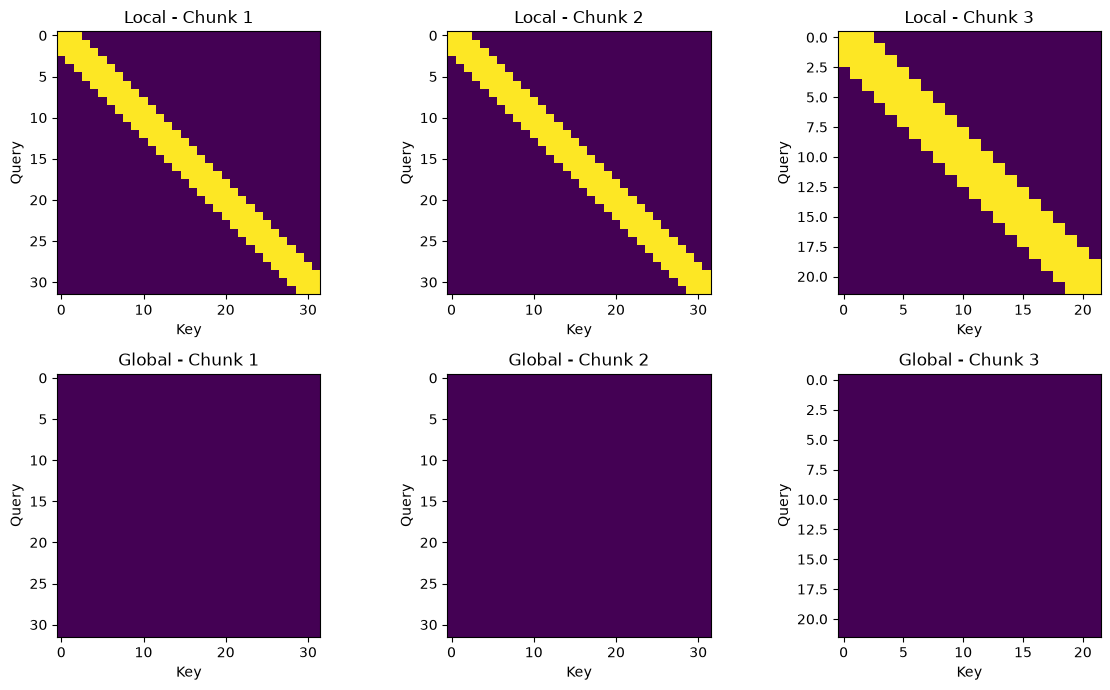

In [94]:
# LOCAL vs GLOBAL
local_processed = process_attention(
    token_chunks,
    mode="local",
    window_size=2
)

global_processed = process_attention(
    token_chunks,
    mode="global",
    window_size=2
)

fig, axes = plt.subplots(
    2,
    len(token_chunks),
    figsize=(12, 7)
)

for i in range(len(token_chunks)):
    axes[0, i].imshow(
        local_processed[i]["mask"]
    )
    axes[0, i].set_title(f"Local - Chunk {i+1}")
    axes[0, i].set_xlabel("Key")
    axes[0, i].set_ylabel("Query")

    axes[1, i].imshow(
        global_processed[i]["mask"]
    )
    axes[1, i].set_title(f"Global - Chunk {i+1}")
    axes[1, i].set_xlabel("Key")
    axes[1, i].set_ylabel("Query")

plt.tight_layout()
plt.show()

In [95]:
# CHATBOT PIPELINE
def generate_chatbot_response(user_text, mode="local", chunk_size=32):
    
    # 1. Split input into token chunks
    chunks = create_token_chunks(
        user_text,
        chunk_size=chunk_size
    )

    # 2. Apply selected attention mode
    processed = process_attention(
        chunks,
        mode=mode,
        window_size=2
    )

    # 3. Prepare context for the LLM
    context = prepare_context(processed)

    # 4. Create chat prompt
    messages = [
        {
            "role": "user",
            "content": context
        }
    ]

    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        text,
        return_tensors="pt"
    )

    # 5. Generate response
    outputs = model.generate(
        **inputs,
        max_new_tokens=200
    )

    response = tokenizer.decode(
        outputs[0][inputs["input_ids"].shape[1]:],
        skip_special_tokens=True
    )

    return response, len(chunks)

In [100]:
response, chunk_count = generate_chatbot_response(
    long_user_input,
    # mode="global"
    mode="local"
)

# print("Attention mode:", "global")
print("Attention mode:", "local")
print("Number of chunks:", chunk_count)
print("\nAssistant:")
print(response)

Attention mode: local
Number of chunks: 3

Assistant:
Certainly! Exploring Thunder Bay, Ontario can offer an incredible array of experiences that cater to various interests. Here's a breakdown of suggested destinations organized by categories: Nature, History & Culture, Food & Drink, Activities, and Points of Interest.

### 1. **Nature**
- **Lake Superior**: A vast body of water that surrounds much of Thunder Bay. It’s ideal for boating, fishing, swimming, and enjoying its natural beauty.
- **Waterfalls**: There are several notable waterfalls within or near Thunder Bay, such as the Silver Beach Falls and the Kettle Falls, offering stunning views and opportunities for photography.
- **Hiking Trails**: The area is rich with hiking trails ranging from easy strolls to challenging hikes like the Boundary Waters Canoe Area Wilderness (BWCAW).
- **Parks**: Several state and provincial parks dot the landscape, including Pukaskwa National Park, where you can enjoy breathtaking scenery and wildl